In [8]:
import torch

In [9]:
words = open('names.txt','r').read().splitlines()


In [10]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [14]:
N = torch.zeros((27,27), dtype=torch.int32)

In [17]:
for w in words:
    chs=['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1][ix2]+=1  

        

In [18]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}

In [ ]:
stoi

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
plt.axis('off');

# mozhno ubrat potom

In [33]:
p = N[0].float()
p = p / p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [36]:
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[ix]

'c'

In [27]:
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
p = p / p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

In [30]:
torch.multinomial(p, num_samples=20, replacement=True, generator=g)

tensor([11, 22, 10, 10, 14,  1, 11, 13,  1,  4,  4, 13, 19, 18, 10, 18, 19,  8,
         1, 13])

In [62]:
P = (N+1).float()
P /= P.sum(1, keepdim=True)

tensor(1.0000)

In [64]:
g = torch.Generator().manual_seed(2147483647)

for i in range(10):
    out = []
    ix = 0
    while True:
        p = P[ix]
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out))


cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [63]:
log_likelihood = 0.0
n=0
for w in words:
    chs=['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2] 
        logprob = torch.log(prob)
        log_likelihood += logprob
        n+=1
        # print(f'{ch1}{ch2}:{prob:.4f} {logprob:.4f}')

print(f'{log_likelihood=}')
nll=-log_likelihood
print(f'{nll=}')
print(f'{nll/n}')

# Loss function without NN is 2.454094171524048
       

log_likelihood=tensor(-559951.5625)
nll=tensor(559951.5625)
2.4543561935424805


In [ ]:
xs, ys = [], []

for w in words[:1]:
    chs=['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)


xs = torch.tensor(xs)
ys = torch.tensor(ys)

        

In [78]:
import torch.nn.functional as F
xenc = F.one_hot(xs, num_classes=27).float()


In [79]:
xenc.shape

torch.Size([12, 27])

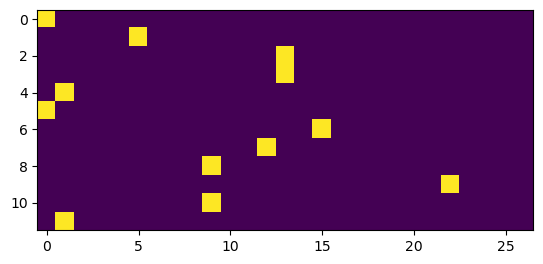

In [81]:
plt.imshow(xenc)

In [84]:
W = torch.randn((27, 27))


In [ ]:
logits = xenc @ W
counts = logits.exp()
prob = counts / counts.sum(1, keepdim=True)

In [86]:
xs

tensor([ 0,  5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1])

In [87]:
ys

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0])

In [88]:
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27),  generator=g, requires_grad=True)

ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()

In [104]:
# Forward pass
xenc = F.one_hot(xs, num_classes=27).float()
logits = xenc @ W
counts = logits.exp()
probs = counts / counts.sum(1, keepdim=True)
loss = - probs[torch.arange(12), ys].log().mean()

In [105]:
# backward pass
W.grad = None
loss.backward()

In [106]:
# Update
W.data += -0.1 * W.grad


In [107]:
print(loss.item())

3.2762205600738525


In [116]:
xs, ys = [], []

for w in words:
    chs=['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)
        


xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of elements:', num)

g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27),  generator=g, requires_grad=True)


number of elements: 228146


In [121]:
for k in range(100):

    # Forward pass
    xenc = F.one_hot(xs, num_classes=27).float()
    logits = xenc @ W
    counts = logits.exp()
    probs = counts / counts.sum(1, keepdim=True)
    loss = - probs[torch.arange(num), ys].log().mean()
    print(loss.item())

    # backward pass
    W.grad = None
    loss.backward()

    # Update
    W.data += -50 * W.grad


# Overall, W.exp() is 'probs' tensor in the begining


2.4726526737213135
2.4724342823028564
2.4722201824188232
2.472010850906372
2.471806049346924
2.4716053009033203
2.4714088439941406
2.471216917037964
2.4710280895233154
2.470843553543091
2.4706623554229736
2.4704854488372803
2.4703118801116943
2.4701414108276367
2.4699742794036865
2.4698104858398438
2.4696500301361084
2.469492197036743
2.4693377017974854
2.4691860675811768
2.4690370559692383
2.468891143798828
2.468747854232788
2.46860671043396
2.468468427658081
2.468332529067993
2.468198776245117
2.4680681228637695
2.4679393768310547
2.4678127765655518
2.46768856048584
2.4675662517547607
2.4674463272094727
2.4673283100128174
2.467211961746216
2.4670979976654053
2.4669854640960693
2.4668750762939453
2.466766834259033
2.4666597843170166
2.466554641723633
2.466451406478882
2.4663493633270264
2.4662487506866455
2.4661505222320557
2.4660532474517822
2.4659576416015625
2.4658634662628174
2.465770721435547
2.465679407119751
2.4655895233154297
2.465500593185425
2.4654133319854736
2.465327262878

Code below shows 20 predictions 

In [126]:
g = torch.Generator().manual_seed(2147483647)


for i in range(20):
    out = []
    ix = 0
    while True:
        xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
        logits = xenc @ W
        counts = logits.exp()
        p = counts / counts.sum(1, keepdim=True)

        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break
    print(''.join(out)) 

cexze.
momasurailezityha.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.
ka.
emimmsade.
eniaviyny.
fobspehinivenvtahlasu.
dsor.
br.
jol.
pen.
aisan.
ja.
